<a href="https://colab.research.google.com/github/yakudza007/CNN_Transfer_Learning/blob/main/CNN_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML102


## Lab: Data Augmentation and Transfer Learning with a Pre-trained CNN

**Amity University Tashkent, Department of Information Technology and Engineering**

**Duration:** 2 hours

| Part | Session | What we do |
|---|---|---|
| Part A | Session 1 (60 min) | Guided walkthrough with explanations and examples |
| Part B | Session 2 (30 min work) | Graded exercises, 3 exercises, 100 marks in total |

### Learning outcomes
By the end of this lab you will be able to:
1. Explain what data augmentation is and why it reduces overfitting.
2. Apply common image augmentations with `torchvision.transforms`.
3. Load a CNN that was pre-trained on ImageNet (ResNet18).
4. Freeze layers and train only a new final layer (feature extraction).
5. Unfreeze some layers and fine-tune them with a small learning rate.
6. Compare a pre-trained model with a CNN trained from scratch.

### Before you start
- This notebook is designed for **Google Colab**. Go to **Runtime > Change runtime type** and select **GPU (T4)**. It also runs on CPU, but training will be much slower.
- Run the cells **in order**, from top to bottom.

---
# PART A: Guided Walkthrough (Session 1)

## 1. Setup
We import the libraries we need and check whether a GPU is available.
- `torch` and `torch.nn` are used to build and train neural networks.
- `torchvision` gives us ready-made datasets, image transforms and pre-trained models.

In [1]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms, models
from datasets import load_dataset     # Hugging Face datasets (pre-installed in Colab)

# Fix the random seeds so everyone gets similar results
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Use the GPU if we have one, otherwise use the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### Lab settings
We keep all important numbers in one place so they are easy to change.

- We use only **3,000 training images** on purpose. Transfer learning is most useful when we have a **small dataset**.
- CIFAR-10 images are tiny (32 x 32 pixels). We resize them to **128 x 128** because the pre-trained model was trained on larger images.

In [2]:
IMG_SIZE = 128      # images are resized to 128 x 128
BATCH_SIZE = 64     # number of images per training step
TRAIN_SIZE = 3000   # number of training images we use (small on purpose)
TEST_SIZE = 1000    # number of test images we use
EPOCHS = 5          # number of passes over the training data in Part A

## 2. The dataset: CIFAR-10
CIFAR-10 has 60,000 small colour images in 10 classes (airplane, automobile, bird, ...).
We load it from Hugging Face with `load_dataset`. The first run downloads it, so it may take a minute.

The class `HFCifar10` wraps the Hugging Face data so that PyTorch can use it:
- `__len__` returns the number of images,
- `__getitem__` returns one (image, label) pair. If we give it a transform, the image is transformed. If not (`transform=None`), we get the normal picture back, which is useful for plotting.

In [3]:
hf_cifar = load_dataset("uoft-cs/cifar10")

class HFCifar10(Dataset):
    def __init__(self, split, transform=None):
        self.data = split
        self.transform = transform
        self.classes = split.features["label"].names

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        row = self.data[i]
        image = row["img"]
        if self.transform is not None:
            image = self.transform(image)
        return image, row["label"]

# Versions without a transform, so images stay as normal pictures
raw_train = HFCifar10(hf_cifar["train"])
raw_test = HFCifar10(hf_cifar["test"])
CLASS_NAMES = raw_train.classes

print("Classes:", CLASS_NAMES)
print("Full training set size:", len(raw_train))
print("Full test set size:", len(raw_test))

# Look at one example
image, label = raw_train[0]
print("Image size:", image.size, "| Label:", label, "=", CLASS_NAMES[label])

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Full training set size: 50000
Full test set size: 10000
Image size: (32, 32) | Label: 0 = airplane


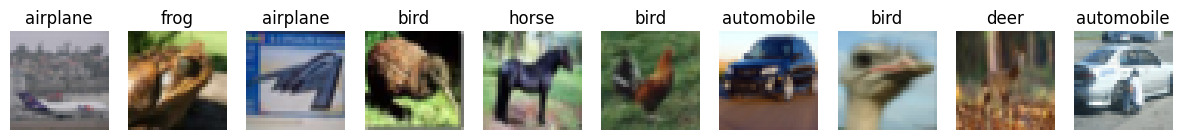

In [4]:
# Show 10 training images with their class names
plt.figure(figsize=(15, 2))
for i in range(10):
    image, label = raw_train[i]
    plt.subplot(1, 10, i + 1)
    plt.imshow(image)
    plt.title(CLASS_NAMES[label])
    plt.axis("off")
plt.show()

### Making a small dataset
We randomly choose 3,000 training images and 1,000 test images.
We save the chosen positions (indices) so that **every model in this lab uses exactly the same images**. This makes the comparison fair.

In [5]:
train_indices = random.sample(range(len(raw_train)), TRAIN_SIZE)
test_indices = random.sample(range(len(raw_test)), TEST_SIZE)

print("Training images we use:", len(train_indices))
print("Test images we use:", len(test_indices))

Training images we use: 3000
Test images we use: 1000


## 3. Data augmentation

### The problem: overfitting
With only 3,000 images, a CNN can **memorise** the training images instead of learning general patterns.
Then training accuracy is high but test accuracy is low. This is called **overfitting**.

### The idea
**Data augmentation** creates new, slightly different versions of each training image every time the model sees it:
- flip it left to right,
- rotate it a little,
- zoom in on part of it,
- change the brightness or contrast.

A cat is still a cat after a small rotation, so the label stays the same. The model sees more variety and learns features that work on new images.

**Important rule:** augmentation is used **only on the training data**. The test data must stay unchanged so that we measure performance on real, normal images.

### Each augmentation on its own
Let us apply each augmentation separately to one image to see what it does.

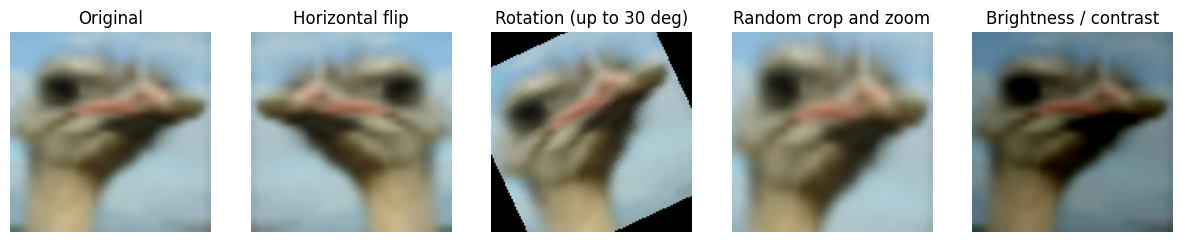

In [6]:
image, label = raw_train[7]
image = image.resize((IMG_SIZE, IMG_SIZE))   # make it bigger so it is easier to see

examples = {
    "Original": image,
    "Horizontal flip": transforms.RandomHorizontalFlip(p=1.0)(image),
    "Rotation (up to 30 deg)": transforms.RandomRotation(degrees=30)(image),
    "Random crop and zoom": transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0))(image),
    "Brightness / contrast": transforms.ColorJitter(brightness=0.5, contrast=0.5)(image),
}

plt.figure(figsize=(15, 3.5))
for i, (name, img) in enumerate(examples.items()):
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")
plt.show()

### Building the transform pipelines
`transforms.Compose` joins several steps into one pipeline. Every image goes through the steps in order.

We need **two pipelines**:
1. `plain_transform` for test images (and for training **without** augmentation): resize, convert to tensor, normalise.
2. `augment_transform` for training **with** augmentation: the same steps plus random changes.

**Why these numbers and not 0.5?** In earlier labs you may have used `Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))`. That is fine for a model trained from scratch. But the pre-trained model learned on ImageNet images that were normalised with the mean and standard deviation below (one value per colour channel: red, green, blue). Our images must be prepared in the same way, so we use these numbers for every model in this lab.

In [7]:
MEAN = [0.485, 0.456, 0.406]   # ImageNet mean for R, G, B
STD = [0.229, 0.224, 0.225]    # ImageNet standard deviation for R, G, B

# Pipeline 1: no augmentation (used for test data)
plain_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),                 # picture -> tensor with values 0 to 1
    transforms.Normalize(MEAN, STD),
])

# Pipeline 2: with augmentation (used for training data only)
augment_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

### Seeing the full augmentation pipeline
The helper function below applies a transform several times to the **same** image and shows the results.
Because the changes are random, every version looks a little different.
(`unnormalize` simply undoes the normalisation so that the picture looks normal on screen.)

Class: bird


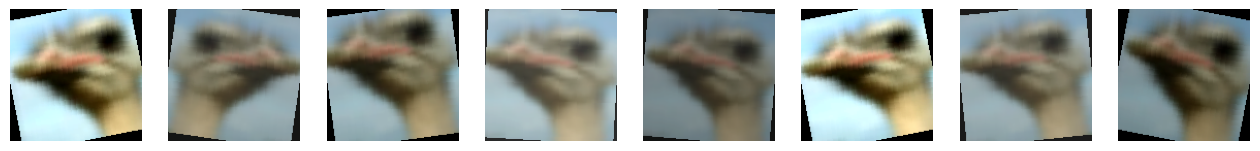

In [9]:
def unnormalize(tensor):
    # tensor shape is (3, H, W); matplotlib wants (H, W, 3)
    img = tensor.permute(1, 2, 0).numpy()
    img = img * np.array(STD) + np.array(MEAN)
    return np.clip(img, 0, 1)

def show_augmented(image, transform, n=8):
    plt.figure(figsize=(2 * n, 2.2))
    for i in range(n):
        result = transform(image)
        if isinstance(result, torch.Tensor):
            result = unnormalize(result)
        plt.subplot(1, n, i + 1)
        plt.imshow(result)
        plt.axis("off")
    plt.show()

image, label = raw_train[7]
print("Class:", CLASS_NAMES[label])
show_augmented(image, augment_transform, n=8)

## 4. Data loaders and training functions

### Data loaders
A `DataLoader` gives the model images in small groups (batches) and shuffles the training data each epoch.
The function below creates a training loader with the transform we choose, and a test loader that **always** uses `plain_transform`.

In [10]:
def make_loaders(train_transform):
    train_data = HFCifar10(hf_cifar["train"], train_transform)
    test_data = HFCifar10(hf_cifar["test"], plain_transform)

    # keep only our small set of images
    train_data = Subset(train_data, train_indices)
    test_data = Subset(test_data, test_indices)

    train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
    return train_loader, test_loader

# Two versions of the training data: without and with augmentation
plain_train_loader, test_loader = make_loaders(plain_transform)
aug_train_loader, test_loader = make_loaders(augment_transform)

images, labels = next(iter(aug_train_loader))
print("One batch of images:", images.shape)   # (batch, channels, height, width)
print("One batch of labels:", labels.shape)

One batch of images: torch.Size([64, 3, 128, 128])
One batch of labels: torch.Size([64])


### Training and evaluation functions
These are the same steps you have used in earlier labs, put into functions so we can reuse them for every model.

`train_model` does the following for each epoch:
1. For each batch: predict, compute the loss, compute gradients (`backward`), update the weights (`step`).
2. Measure accuracy on the training data and on the test data.

**Note:** the optimizer only receives parameters that have `requires_grad = True`. Frozen layers (Section 6) are therefore never updated.

`count_parameters` shows how many weights a model has and how many of them will be trained.

In [11]:
def evaluate(model, loader):
    model.eval()                       # evaluation mode
    correct = 0
    total = 0
    with torch.no_grad():              # no gradients needed for testing
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total


def train_model(model, train_loader, test_loader, epochs=EPOCHS, lr=0.001):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()

    # only give the optimizer the parameters that are NOT frozen
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)

    history = {"train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()                  # training mode
        correct = 0
        total = 0
        start = time.time()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()              # 1. clear old gradients
            outputs = model(images)            # 2. forward pass
            loss = loss_fn(outputs, labels)    # 3. compute loss
            loss.backward()                    # 4. compute gradients
            optimizer.step()                   # 5. update weights

            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_acc = 100 * correct / total
        test_acc = evaluate(model, test_loader)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(f"Epoch {epoch + 1}/{epochs} | train acc: {train_acc:.1f}% "
              f"| test acc: {test_acc:.1f}% | time: {time.time() - start:.0f}s")

    return history


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total parameters:     {total:,}")
    print(f"Trainable parameters: {trainable:,}")


results = {}   # we store the history of every model here to compare them later

## 5. Baseline: a CNN trained from scratch

"From scratch" means the weights start as **random numbers**. The model must learn everything (edges, shapes, objects) from our 3,000 images only.

Our simple CNN has 4 blocks of Convolution + ReLU + MaxPooling. Each MaxPool halves the image size:
128 to 64 to 32 to 16 to 8. So after the last block we have 128 feature maps of size 8 x 8, which gives 128 x 8 x 8 = 8,192 numbers for the classifier.

In [12]:
def build_simple_cnn():
    model = nn.Sequential(
        # Block 1: 3 colour channels -> 32 feature maps, size 128 -> 64
        nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        # Block 2: 32 -> 64 feature maps, size 64 -> 32
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        # Block 3: 64 -> 128 feature maps, size 32 -> 16
        nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        # Block 4: 128 -> 128 feature maps, size 16 -> 8
        nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        # Classifier
        nn.Flatten(),
        nn.Linear(128 * 8 * 8, 256), nn.ReLU(),
        nn.Linear(256, 10),            # 10 classes
    )
    return model

scratch_model = build_simple_cnn()
count_parameters(scratch_model)

Total parameters:     2,340,810
Trainable parameters: 2,340,810


### 5.1 Scratch CNN without augmentation

In [13]:
torch.manual_seed(0)
model = build_simple_cnn()
results["Scratch CNN, no augmentation"] = train_model(model, plain_train_loader, test_loader, lr=0.001)

Epoch 1/5 | train acc: 23.0% | test acc: 32.4% | time: 10s
Epoch 2/5 | train acc: 35.9% | test acc: 40.3% | time: 7s
Epoch 3/5 | train acc: 44.7% | test acc: 45.0% | time: 7s
Epoch 4/5 | train acc: 50.3% | test acc: 47.6% | time: 7s
Epoch 5/5 | train acc: 56.4% | test acc: 47.6% | time: 7s


### 5.2 Scratch CNN with augmentation
Same model, same number of epochs. The only change is the training data loader.

In [14]:
torch.manual_seed(0)
model = build_simple_cnn()
results["Scratch CNN, with augmentation"] = train_model(model, aug_train_loader, test_loader, lr=0.001)

Epoch 1/5 | train acc: 19.9% | test acc: 30.7% | time: 12s
Epoch 2/5 | train acc: 32.6% | test acc: 37.5% | time: 12s
Epoch 3/5 | train acc: 38.1% | test acc: 41.5% | time: 12s
Epoch 4/5 | train acc: 42.0% | test acc: 43.8% | time: 12s
Epoch 5/5 | train acc: 45.6% | test acc: 47.3% | time: 12s


### What to look at
Compare the **gap between training accuracy and test accuracy** for the two runs.
- Without augmentation, the gap is usually larger: the model is starting to memorise the training images.
- With augmentation, training is "harder", so training accuracy rises more slowly, but the gap stays smaller.
- With longer training (more epochs), the benefit of augmentation becomes even clearer.

In both cases, test accuracy stays fairly low, because 3,000 images are simply not enough to learn good features from zero. This is where transfer learning helps.

## 6. Transfer learning with a pre-trained ResNet18

### The idea
**Transfer learning** means reusing a model that was already trained on a very large dataset for a new task.

ResNet18 was trained on **ImageNet**: about 1.2 million images in 1,000 classes. While learning, its layers built up useful features:
- **early layers** detect simple things: edges, colours, textures,
- **middle layers** detect shapes and parts: wheels, eyes, wings,
- **last layers** combine these parts into whole objects.

These features are also useful for our 10 CIFAR-10 classes. We keep the learned layers and replace only the **last layer** (the one that outputs 1,000 ImageNet classes) with a new layer that outputs **10 classes**.

### Loading the pre-trained model
The first time, PyTorch downloads the trained weights (about 45 MB).

In [15]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# The main parts of ResNet18
for name, part in resnet.named_children():
    print(name)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]

conv1
bn1
relu
maxpool
layer1
layer2
layer3
layer4
avgpool
fc


ResNet18 is made of these parts, in order:
- `conv1`, `bn1`, `relu`, `maxpool`: the first convolution block,
- `layer1`, `layer2`, `layer3`, `layer4`: four groups of residual blocks (early to late features),
- `avgpool`: turns each of the 512 feature maps into one number,
- `fc`: the final fully connected layer, which gives the class scores.

Let us look at the final layer.

In [16]:
print(resnet.fc)
count_parameters(resnet)

Linear(in_features=512, out_features=1000, bias=True)
Total parameters:     11,689,512
Trainable parameters: 11,689,512


`in_features=512, out_features=1000` means: 512 features come in, 1,000 ImageNet class scores come out.
We need 10 outputs, so we will replace this layer.

There are two main ways to use a pre-trained model:

| Strategy | What is trained | When to use |
|---|---|---|
| **Feature extraction** | Only the new last layer. All other layers are frozen. | Very small dataset, images similar to ImageNet |
| **Fine-tuning** | The new last layer plus some of the last pre-trained layers | More data, or images a bit different from ImageNet |

### 6.1 Strategy 1: Feature extraction (freeze all layers)
**Freezing** a layer means its weights will not change during training. In PyTorch we freeze a parameter by setting `requires_grad = False`, so no gradient is computed for it.

Steps:
1. Load the pre-trained model.
2. Freeze **all** parameters.
3. Replace `fc` with a new `nn.Linear(512, 10)`. A new layer is trainable by default, so it is the only part that learns.

In [17]:
# Step 1: load the pre-trained model
fe_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Step 2: freeze all parameters
for param in fe_model.parameters():
    param.requires_grad = False

# Step 3: replace the last layer (new layer = trainable)
fe_model.fc = nn.Linear(512, 10)

count_parameters(fe_model)

Total parameters:     11,181,642
Trainable parameters: 5,130


Only **5,130** of about 11 million parameters will be trained (512 x 10 weights + 10 biases).
Training is fast, and with so few trainable weights the model cannot easily overfit.

In [18]:
torch.manual_seed(0)
results["ResNet18, feature extraction"] = train_model(fe_model, aug_train_loader, test_loader, lr=0.001)

Epoch 1/5 | train acc: 30.0% | test acc: 42.8% | time: 11s
Epoch 2/5 | train acc: 50.7% | test acc: 55.8% | time: 11s
Epoch 3/5 | train acc: 57.2% | test acc: 58.7% | time: 11s
Epoch 4/5 | train acc: 59.2% | test acc: 63.4% | time: 11s
Epoch 5/5 | train acc: 60.8% | test acc: 62.7% | time: 12s


### 6.2 Strategy 2: Fine-tuning (unfreeze the last block)
Now we also allow the **last residual group (`layer4`)** to change, so its features can adapt to CIFAR-10.

Steps:
1. Load the pre-trained model.
2. Freeze all parameters.
3. **Unfreeze** `layer4` by setting `requires_grad = True` for its parameters.
4. Replace `fc` with a new layer.

**Use a small learning rate (0.0001 instead of 0.001).** The pre-trained weights are already good. A large learning rate would make big changes and could destroy what the model learned on ImageNet. We only want to adjust them gently.

In [19]:
# Step 1: load the pre-trained model
ft_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Step 2: freeze all parameters
for param in ft_model.parameters():
    param.requires_grad = False

# Step 3: unfreeze the last residual group
for param in ft_model.layer4.parameters():
    param.requires_grad = True

# Step 4: replace the last layer
ft_model.fc = nn.Linear(512, 10)

count_parameters(ft_model)

Total parameters:     11,181,642
Trainable parameters: 8,398,858


In [20]:
torch.manual_seed(0)
results["ResNet18, fine-tuning layer4"] = train_model(ft_model, aug_train_loader, test_loader, lr=0.0001)

Epoch 1/5 | train acc: 50.5% | test acc: 69.0% | time: 12s
Epoch 2/5 | train acc: 72.0% | test acc: 76.8% | time: 11s
Epoch 3/5 | train acc: 79.2% | test acc: 81.1% | time: 12s
Epoch 4/5 | train acc: 83.3% | test acc: 80.8% | time: 12s
Epoch 5/5 | train acc: 85.4% | test acc: 84.0% | time: 12s


## 7. Comparing all models
We print the final accuracies in a table and plot the test accuracy after each epoch.

In [21]:
print(f"{'Model':35s} {'Train acc':>10s} {'Test acc':>10s} {'Gap':>8s}")
print("-" * 66)
for name, history in results.items():
    train_acc = history["train_acc"][-1]
    test_acc = history["test_acc"][-1]
    print(f"{name:35s} {train_acc:9.1f}% {test_acc:9.1f}% {train_acc - test_acc:7.1f}")

Model                                Train acc   Test acc      Gap
------------------------------------------------------------------
Scratch CNN, no augmentation             56.4%      47.6%     8.8
Scratch CNN, with augmentation           45.6%      47.3%    -1.7
ResNet18, feature extraction             60.8%      62.7%    -1.9
ResNet18, fine-tuning layer4             85.4%      84.0%     1.4


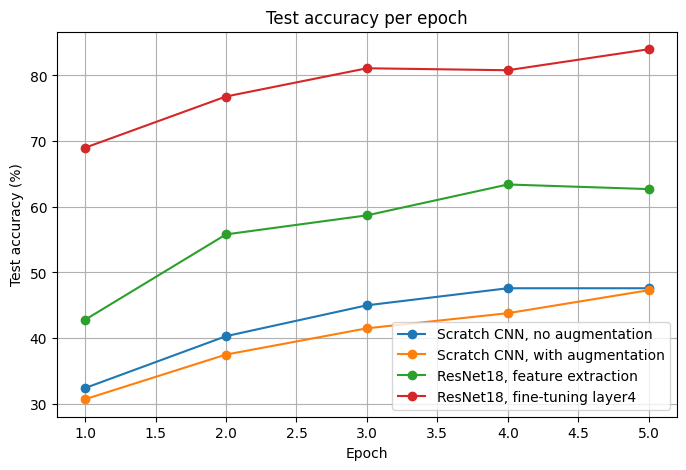

In [22]:
plt.figure(figsize=(8, 5))
for name, history in results.items():
    epochs = range(1, len(history["test_acc"]) + 1)
    plt.plot(epochs, history["test_acc"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Test accuracy (%)")
plt.title("Test accuracy per epoch")
plt.legend()
plt.grid(True)
plt.show()

### Discussion points
1. **Pre-trained versus scratch:** both ResNet18 models should be far more accurate than the scratch CNN, even after only one epoch. They start with features learned from 1.2 million images, while the scratch CNN starts from random weights.
2. **Feature extraction versus fine-tuning:** fine-tuning usually gives a higher accuracy because `layer4` can adapt to our images. It trains more parameters, so each epoch takes longer, and with a very small dataset it can overfit more easily.
3. **Augmentation:** it reduces the gap between training and test accuracy. It costs nothing extra in data collection.

## 8. Summary
- **Data augmentation** creates random variations of training images. It reduces overfitting. Apply it to training data only.
- **Transfer learning** reuses a model trained on a large dataset.
- **Freezing** a layer: `param.requires_grad = False`. Its weights do not change.
- **Feature extraction:** freeze everything, train only a new last layer.
- **Fine-tuning:** also unfreeze the last pre-trained layers and train with a **small learning rate**.
- With a small dataset, a pre-trained model almost always beats a model trained from scratch.

| Your situation | Suggested approach |
|---|---|
| Small dataset, images similar to ImageNet | Feature extraction |
| Medium dataset, or images different from ImageNet | Fine-tune the last layers |
| Very large dataset | Fine-tune the whole network, or train from scratch |

---
# PART B: Graded Exercises (Session 2)

**Total: 100 marks. Suggested time: 30 minutes.**

| Exercise | Topic | Marks |
|---|---|---|
| Exercise 1 | Build and test your own augmentation pipeline | 30 |
| Exercise 2 | Transfer learning by feature extraction | 40 |
| Exercise 3 | Fine-tuning and comparison | 30 |
| **Total** | | **100** |

### Instructions
- Part B uses the data, `HFCifar10`, `make_loaders`, `train_model`, `count_parameters` and `show_augmented` from Part A. **Run Part A Sections 1 to 4 first** if you restarted the notebook. You do not need to re-run the training in Sections 5 to 7.
- Write your code where you see `# YOUR CODE HERE`. Replace every `___` with the correct value.
- Write your written answers in the markdown cells marked **Your answer**.
- To keep the time short, every model in Part B trains for **3 epochs**.
- When you finish, run all your Part B cells, save the notebook as `AIML302_Lab_YourName_YourID.ipynb` and submit it.

## Exercise 1: Your own augmentation pipeline (30 marks)

**1(a) (10 marks)** Create a transform called `my_augment_transform` with these steps, in this order:
1. Resize to `(IMG_SIZE, IMG_SIZE)`
2. Random horizontal flip with probability 0.5
3. Random rotation of up to **20** degrees
4. Colour jitter with brightness **0.4**
5. Convert to tensor
6. Normalise with `MEAN` and `STD`

In [23]:
# Exercise 1(a)
my_augment_transform = transforms.Compose([
    # YOUR CODE HERE
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.4, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
print(my_augment_transform)

Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(128, 128), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.7, 1.3), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


**1(b) (10 marks)** Use the function `show_augmented` to display **6** augmented versions of the training image at index **25** (`raw_train[25]`) using your `my_augment_transform`. Also print the class name of the image.

Class: bird


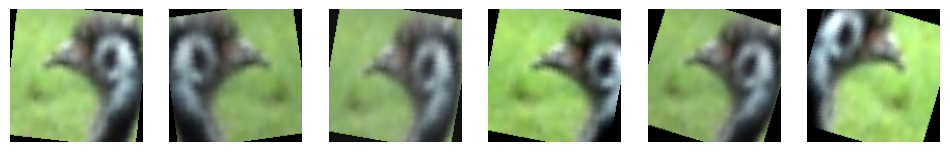

In [25]:
# Exercise 1(b)
# YOUR CODE HERE
image, label = raw_train[25]
print("Class:", CLASS_NAMES[label])
show_augmented(image, my_augment_transform, n=6)

**1(c) (10 marks)** Answer in 1 to 2 sentences each.
1. Why do we apply data augmentation to the **training** data but **not** to the test data? (5 marks)
2. Give one augmentation that would be a **bad** choice for a dataset of handwritten digits (0 to 9), and explain why. (5 marks)

**Your answer:**
1. We always use augmentation on training dataset. Because in test dataset shoul be origanal data. Otherwise it become oferfitting
2. Example for handwritten augmentation is flipping 6 to horizontal. So, it will change to 9. It will be changed totally to another number. The meaning of number will dromatically changed.

## Exercise 2: Transfer learning by feature extraction (40 marks)

Build a pre-trained ResNet18 where **only the new last layer** is trained.

**2(a) (5 marks)** Load a pre-trained ResNet18 into a variable called `model_fe`.

**2(b) (10 marks)** Freeze **all** of its parameters.

**2(c) (10 marks)** Replace the last layer `fc` with a new linear layer for our **10** classes.

In [28]:
# Exercise 2(a)
model_fe = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Exercise 2(b)
for param in model_fe.parameters():
    param.requires_grad = False
    #  (use a for loop over model_fe.parameters())


# Exercise 2(c)
model_fe.fc = nn.Linear(512, 10)


**2(d) (5 marks)** Use `count_parameters` to print the total and trainable parameters of `model_fe`. Then write below how many parameters are trainable and why it is this number.

In [29]:
# Exercise 2(d)
count_parameters(model_fe)

Total parameters:     11,181,642
Trainable parameters: 5,130


**Your answer: 5130 parameters are trainable. Because training is fast, and with so few trainable weights the model cannot easily overfit.**

**2(e) (10 marks)**
1. Use `make_loaders` with **your** `my_augment_transform` from Exercise 1 to create `my_train_loader` and `my_test_loader`.
2. Train `model_fe` with `train_model` for **3 epochs** with learning rate **0.001**. Save the result in `history_fe`.
3. Print the final test accuracy.

In [30]:
# Exercise 2(e)
torch.manual_seed(0)

my_train_loader, my_test_loader = make_loaders(my_augment_transform)   # YOUR CODE HERE

history_fe = train_model(model_fe, my_train_loader, my_test_loader, epochs=3, lr=0.001)

print("Final test accuracy:", history_fe["test_acc"][-1])

Epoch 1/3 | train acc: 28.4% | test acc: 46.3% | time: 12s
Epoch 2/3 | train acc: 51.1% | test acc: 59.1% | time: 11s
Epoch 3/3 | train acc: 56.3% | test acc: 62.7% | time: 11s
Final test accuracy: 62.7


## Exercise 3: Fine-tuning and comparison (30 marks)

This time you fine-tune **two** residual groups: `layer3` **and** `layer4`.

**3(a) (10 marks)** Create `model_ft`:
1. Load a pre-trained ResNet18.
2. Freeze all parameters.
3. Unfreeze the parameters of `layer3` and `layer4`.
4. Replace `fc` with a new layer for 10 classes.
5. Print the parameter counts with `count_parameters`.

In [31]:
# Exercise 3(a)
model_ft =  models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# freeze all parameters
for param in model_ft.parameters():
    param.requires_grad = False


# unfreeze layer3 and layer4
for param in model_ft.layer3.parameters():
    param.requires_grad = True
for param in model_ft.layer4.parameters():
    param.requires_grad = True


# new last layer
model_ft.fc = nn.Linear(512, 10)


count_parameters(model_ft)

Total parameters:     11,181,642
Trainable parameters: 10,498,570


**3(b) (5 marks)** Train `model_ft` for **3 epochs** with learning rate **0.0001**, using `my_train_loader` and `my_test_loader`. Save the result in `history_ft`.

In [32]:
# Exercise 3(b)
torch.manual_seed(0)
history_ft = train_model(model_ft, my_train_loader, my_test_loader, epochs=3, lr=0.0001)

print("Final test accuracy:", history_ft["test_acc"][-1])

Epoch 1/3 | train acc: 51.7% | test acc: 69.5% | time: 13s
Epoch 2/3 | train acc: 77.0% | test acc: 78.3% | time: 13s
Epoch 3/3 | train acc: 82.8% | test acc: 84.8% | time: 13s
Final test accuracy: 84.8


**3(c) (5 marks)** Fill in the table with your final test accuracies. For the scratch CNN, use the result of Part A Section 5.2 (if you did not run it, use the number shown during the lecture).

**Your answer:**

| Model | Final test accuracy (%) |
|---|---|
| Scratch CNN with augmentation (Part A, 5 epochs) | 46.5%|
| ResNet18 feature extraction (Exercise 2, 3 epochs) |62.7% |
| ResNet18 fine-tuning layer3 + layer4 (Exercise 3, 3 epochs) | 84.4%|

**3(d) (10 marks)** Answer in 1 to 3 sentences each.
1. Why do we use a **smaller** learning rate (0.0001) for fine-tuning than for training the new last layer only (0.001)? (5 marks)
2. The ResNet18 models trained for fewer epochs than the scratch CNN, but they are much more accurate. Explain why. (5 marks)

**Your answer:**
1. We use a smaller learning rate because the pre-trained weights are already very good. A large learning rate would make too big changes and ruin the useful features learned on ImageNet.
2. ResNet18 starts with smart weights that already know how to recognize shapes, colors, and patterns from 1.2 million images. The scratch CNN starts with random weights and has to learn everything from zero.

---
**End of lab.** Save your notebook and submit it.